In [1]:

# HAM10000 MODEL IMPROVEMENT — SETUP

import os
import shutil
import zipfile
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from PIL import Image
from google.colab import drive
from torchvision import transforms
from torchvision.models import resnet18
from torch.utils.data import Dataset, DataLoader

# 1. Connect Google Drive
drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/DMML Project")
DATA = PROJECT / "data"
CNN = PROJECT / "CNN Results" / "ResNet18"
IMPROVEMENT = CNN / "Improvement_Experiment"

IMPROVEMENT.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda", "Enable T4 GPU first."

# 2. Reproducibility
random.seed(123)
np.random.seed(123)
torch.manual_seed(123)
torch.cuda.manual_seed_all(123)

# 3. Load original metadata and splits
df = pd.read_csv(DATA / "HAM10000_metadata.csv")
splits = pd.read_csv(DATA / "HAM10000_splits.csv")

df = df.merge(
    splits[["image_id", "split"]],
    on="image_id",
    validate="one_to_one"
)

assert len(df) == 10015
assert df.groupby("lesion_id")["split"].nunique().max() == 1
assert df["split"].value_counts().to_dict() == {
    "train": 7169, "val": 1424, "test": 1422
}

# 4. Restore images
image_folder = Path("/content/HAM10000_images")
image_folder.mkdir(exist_ok=True)

zip_folder = PROJECT / "HAM10000 Images"

for part in [1, 2]:
    filename = f"HAM10000_images_part_{part}.zip"
    local_zip = Path("/content") / filename

    # Copy from Drive to local storage if necessary
    if not local_zip.exists():
        print("Copying", filename)
        shutil.copy2(zip_folder / filename, local_zip)

    print("Extracting", filename)
    with zipfile.ZipFile(local_zip, "r") as z:
        z.extractall(image_folder)

# Find all images
image_paths = [
    p for p in image_folder.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

image_dict = {p.stem: str(p) for p in image_paths}

assert len(image_paths) == 10015
assert len(image_dict) == 10015
assert set(df["image_id"]) == set(image_dict)

# 5. Class mapping
classes = sorted(df["dx"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

# ResNet18 ImageNet normalisation
resnet_mean = [0.485, 0.456, 0.406]
resnet_std = [0.229, 0.224, 0.225]

# Same augmentation as our original experiment
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(resnet_mean, resnet_std)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(resnet_mean, resnet_std)
])

# 6. Dataset class
class HAM10000Dataset(Dataset):
    def __init__(self, data, transform):
        self.data = data.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        with Image.open(image_dict[row["image_id"]]) as im:
            image = im.convert("RGB")

        image = self.transform(image)
        label = class_to_idx[row["dx"]]

        return image, label

train_dataset = HAM10000Dataset(
    df[df["split"] == "train"], train_transform
)

val_dataset = HAM10000Dataset(
    df[df["split"] == "val"], val_transform
)

train_loader = DataLoader(
    train_dataset, batch_size=32,
    shuffle=True, num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=32,
    shuffle=False, num_workers=2, pin_memory=True
)

# 7. Rebuild ResNet18
model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 7)

# Load our existing best fine-tuned checkpoint
original_path = CNN / "best_resnet18_finetuned.pth"

checkpoint = torch.load(
    original_path, map_location="cpu",
    weights_only=True
)

assert checkpoint["classes"] == classes

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)

# Freeze earlier layers
for param in model.parameters():
    param.requires_grad = False

# Fine-tune final residual block and classifier
for param in model.layer4.parameters():
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

# 8. Recreate class weights
train_counts = (
    df[df["split"] == "train"]["dx"]
    .value_counts().reindex(classes)
)

weights = (
    len(train_dataset) /
    (len(classes) * train_counts.values)
)

class_weights = torch.tensor(
    weights, dtype=torch.float32, device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

print("\nSETUP COMPLETE!")
print("Device:", device)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Classes:", classes)
print("Original checkpoint loaded:", checkpoint["epoch"])
print("Original best Macro F1:",
      checkpoint["best_val_macro_f1"])
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))
print("Improvement folder:", IMPROVEMENT)


Mounted at /content/drive
Copying HAM10000_images_part_1.zip
Extracting HAM10000_images_part_1.zip
Copying HAM10000_images_part_2.zip
Extracting HAM10000_images_part_2.zip

SETUP COMPLETE!
Device: cuda
Training images: 7169
Validation images: 1424
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Original checkpoint loaded: 3
Original best Macro F1: 0.4857085659732026
Trainable parameters: 8397319
Improvement folder: /content/drive/MyDrive/DMML Project/CNN Results/ResNet18/Improvement_Experiment


In [2]:

# IMPROVED RESNET18 TRAINING

from sklearn.metrics import f1_score, accuracy_score

optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4}
])

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

max_epochs = 20
early_stop_patience = 5
no_improvement = 0

# Start from the previous validation benchmark
best_f1 = 0.4857
history = []

best_path = IMPROVEMENT / "best_improved_resnet18.pth"
history_path = IMPROVEMENT / "improvement_history.csv"

# Save the starting model as the initial best candidate
torch.save({
    "model_state_dict": model.state_dict(),
    "best_val_macro_f1": best_f1,
    "epoch": 0,
    "classes": classes
}, best_path)

for epoch in range(max_epochs):

    # Keep BatchNorm running statistics frozen
    model.eval()

    train_loss_sum = 0
    train_correct = 0
    train_total = 0

    # Training
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += labels.size(0)

    # Validation
    model.eval()
    val_preds = []
    val_true = []
    val_loss_sum = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)

            val_preds.extend(outputs.argmax(1).cpu().tolist())
            val_true.extend(labels.cpu().tolist())

    train_loss = train_loss_sum / train_total
    val_loss = val_loss_sum / len(val_dataset)

    val_acc = accuracy_score(val_true, val_preds)
    val_f1 = f1_score(
        val_true, val_preds,
        average="macro", zero_division=0
    )

    scheduler.step(val_f1)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_correct / train_total,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1
    })

    pd.DataFrame(history).to_csv(history_path, index=False)

    if val_f1 > best_f1:
        best_f1 = val_f1
        no_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "best_val_macro_f1": best_f1,
            "epoch": epoch + 1,
            "classes": classes
        }, best_path)

        print("New best model saved!")
    else:
        no_improvement += 1

    print(
        f"Epoch {epoch+1}/{max_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f} | "
        f"Val Macro F1: {val_f1:.4f} | "
        f"Best: {best_f1:.4f}"
    )

    if no_improvement >= early_stop_patience:
        print("Early stopping triggered.")
        break

print("\nTraining finished!")
print("Best validation Macro F1:", round(best_f1, 4))
print("Original benchmark: 0.4857")
print("Model saved:", best_path)
print("History saved:", history_path)


Epoch 1/20 | Train Loss: 0.8169 | Val Loss: 1.0150 | Val Accuracy: 0.6173 | Val Macro F1: 0.4354 | Best: 0.4857
New best model saved!
Epoch 2/20 | Train Loss: 0.7763 | Val Loss: 0.8803 | Val Accuracy: 0.6868 | Val Macro F1: 0.5098 | Best: 0.5098
New best model saved!
Epoch 3/20 | Train Loss: 0.7259 | Val Loss: 1.0584 | Val Accuracy: 0.6447 | Val Macro F1: 0.5248 | Best: 0.5248
New best model saved!
Epoch 4/20 | Train Loss: 0.6534 | Val Loss: 0.9599 | Val Accuracy: 0.6608 | Val Macro F1: 0.5274 | Best: 0.5274
New best model saved!
Epoch 5/20 | Train Loss: 0.6261 | Val Loss: 0.8576 | Val Accuracy: 0.7001 | Val Macro F1: 0.5549 | Best: 0.5549
Epoch 6/20 | Train Loss: 0.6187 | Val Loss: 0.9152 | Val Accuracy: 0.6671 | Val Macro F1: 0.4921 | Best: 0.5549
Epoch 7/20 | Train Loss: 0.5879 | Val Loss: 0.8346 | Val Accuracy: 0.7093 | Val Macro F1: 0.5049 | Best: 0.5549
Epoch 8/20 | Train Loss: 0.5792 | Val Loss: 0.8348 | Val Accuracy: 0.6966 | Val Macro F1: 0.5164 | Best: 0.5549
New best model s


 Original ResNet18
              precision    recall  f1-score   support

       akiec       0.32      0.83      0.46        35
         bcc       0.56      0.64      0.60       113
         bkl       0.40      0.57      0.47       162
          df       0.18      0.64      0.29        14
         mel       0.35      0.62      0.44       141
          nv       0.95      0.62      0.75       939
        vasc       0.26      0.75      0.39        20

    accuracy                           0.62      1424
   macro avg       0.43      0.67      0.49      1424
weighted avg       0.77      0.62      0.66      1424



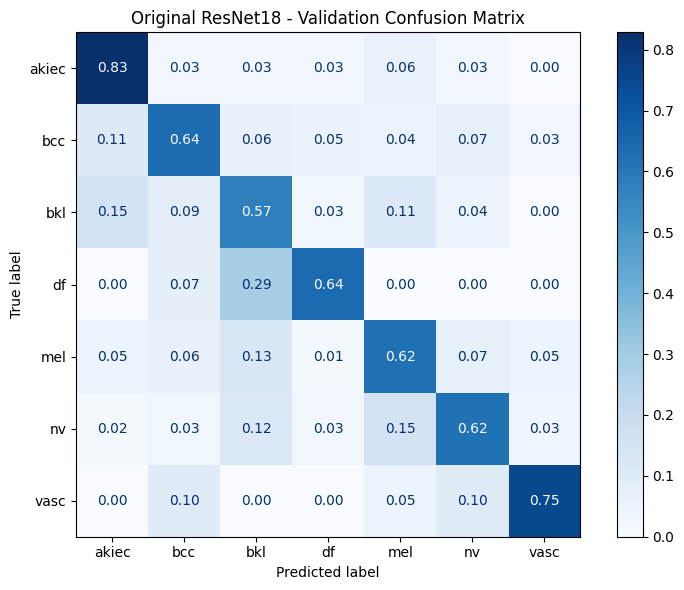


 Improved ResNet18
              precision    recall  f1-score   support

       akiec       0.35      0.77      0.48        35
         bcc       0.76      0.68      0.72       113
         bkl       0.51      0.64      0.57       162
          df       0.53      0.64      0.58        14
         mel       0.38      0.68      0.49       141
          nv       0.95      0.76      0.84       939
        vasc       0.48      0.75      0.59        20

    accuracy                           0.73      1424
   macro avg       0.57      0.70      0.61      1424
weighted avg       0.81      0.73      0.75      1424



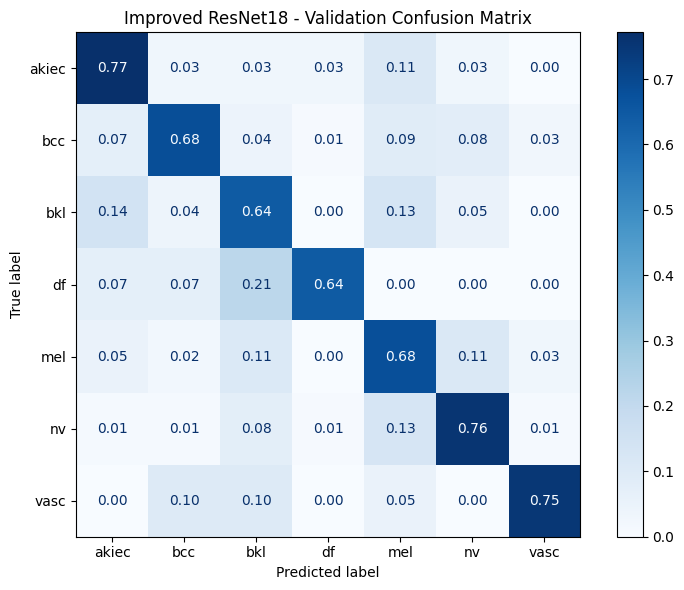


OVERALL COMPARISON


,Model,Accuracy,Balanced Accuracy,Macro F1
0,Original ResNet18,0.6236,0.6681,0.4857
1,Improved ResNet18,0.7282,0.7034,0.6103



PER-CLASS RECALL


,Class,Original Recall,Improved Recall
0,akiec,0.8286,0.7714
1,bcc,0.6372,0.6814
2,bkl,0.5741,0.6420
3,df,0.6429,0.6429
4,mel,0.6241,0.6809
5,nv,0.6198,0.7551
6,vasc,0.7500,0.7500



Comparison saved to Google Drive!


In [3]:

# COMPARE ORIGINAL VS IMPROVED RESNET18

import torch
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

checkpoints = {
    "Original ResNet18": original_path,
    "Improved ResNet18": (
        IMPROVEMENT / "best_improved_resnet18.pth"
    )
}

comparison = []
per_class_reports = {}

for name, path in checkpoints.items():

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=True
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()

    actual = []
    predicted = []

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images.to(device))
            predicted.extend(outputs.argmax(1).cpu().tolist())
            actual.extend(labels.tolist())

    accuracy = accuracy_score(actual, predicted)
    balanced = balanced_accuracy_score(actual, predicted)
    macro_f1 = f1_score(
        actual, predicted, average="macro", zero_division=0
    )

    comparison.append({
        "Model": name,
        "Accuracy": accuracy,
        "Balanced Accuracy": balanced,
        "Macro F1": macro_f1
    })

    report = classification_report(
        actual, predicted,
        labels=list(range(len(classes))),
        target_names=classes,
        output_dict=True,
        zero_division=0
    )

    per_class_reports[name] = report

    print("\n", name)
    print(classification_report(
        actual, predicted,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0
    ))

    fig, ax = plt.subplots(figsize=(8, 6))

    ConfusionMatrixDisplay.from_predictions(
        actual, predicted,
        labels=list(range(len(classes))),
        display_labels=classes,
        normalize="true",
        cmap="Blues",
        values_format=".2f",
        ax=ax
    )

    ax.set_title(name + " - Validation Confusion Matrix")
    plt.tight_layout()

    fig.savefig(
        IMPROVEMENT /
        (name.lower().replace(" ", "_") + "_confusion.png"),
        dpi=300
    )
    plt.show()

# Overall model comparison
comparison_df = pd.DataFrame(comparison)

print("\nOVERALL COMPARISON")
display(comparison_df.round(4))

# Per-class recall comparison
recall_df = pd.DataFrame({
    "Class": classes,
    "Original Recall": [
        per_class_reports["Original ResNet18"][c]["recall"]
        for c in classes
    ],
    "Improved Recall": [
        per_class_reports["Improved ResNet18"][c]["recall"]
        for c in classes
    ]
})

print("\nPER-CLASS RECALL")
display(recall_df.round(4))

comparison_df.to_csv(
    IMPROVEMENT / "model_comparison.csv",
    index=False
)

recall_df.to_csv(
    IMPROVEMENT / "per_class_recall_comparison.csv",
    index=False
)

print("\nComparison saved to Google Drive!")
